# Stress Detection using Machine Learning
## Deepak Dhinwa
## Roll no. : 23B2149

## About the Dataset
#### Synthetic Health Sensor Data From Wearables With Stress Labels
- WESAD, a new publicly available dataset for wearable stress and affect detection
- This multimodal dataset features physiological and motion data, recorded from both a wrist- and a chest-worn device
- Here wee used a synthetic dataset created from training GANs on the WESAD dataset
- Generated using a DGAN
- Features data for 10,000 subjects instead of just 15 found in the original
- An important difference to the original is the reduction of labels to only: stress and non-stress
- link : Can't able to get the link of this synthetic dataset but got link for the orginal (https://uni-siegen.sciebo.de/s/HGdUkoNlW1Ub0Gx/download)

#### Dataset used in training and testing
- We used a subset of the above mention large dataset
- We done some prepreocessing on the Dataset like handling missing values, handling skewness and handling outliers (in different way) in stage 2
- I'm uploading the drive link of this new dataset
- link : https://drive.google.com/file/d/1GA3uIod8d_jHtk2IIwCEYX5AmmNkTaTD/view?usp=sharing

#### Source of code -> Developed completely by me
- Help from ChatGPT is taken

## Loading Dependencies

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression

## Loading and Preprocessing Dataset
- Loading the dataset
- Splitting Dataset into features and target matrix
- Normalizing the dataset
- Splitting further into Train and Test sets

In [5]:
df = pd.read_csv("dataset.csv")
df.head(5)

,BVP,EDA,ACC_x,ACC_y,ACC_z,TEMP,Label
0,0.238061,0.058668,0.679059,0.546219,0.101528,0.832719,0.0
1,0.512416,0.169799,0.862687,0.289050,0.377825,0.971284,0.0
2,0.633430,0.033903,0.311667,0.352741,0.741557,0.905328,0.0
3,0.527648,0.065267,0.384237,0.895484,0.941244,0.132496,0.0
4,0.676393,0.270106,0.408717,0.059676,0.141336,0.888549,0.0


In [6]:
X = df.drop(columns=['Label'])
y = df['Label']

#### Normalization (StandardScalar)
- Scales features so they have zero mean and unit variance
- Prevents models from being biased toward features with larger numeric ranges

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#### Splitting into Training and Test sets

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

## Model Training & Grid Search

#### XGBoost Classifier
- Handles non-linear relationships between sensor data and stress levels
- Built-in regularization to prevent overfitting
- Faster and more accurate than many other ensemble methods due to gradient boosting optimization
- Excellent performance on tabular datasets

#### Why XGBoost (Tree-Based Model) for Stress Detection?

- **Best for Tabular Data**: Tree models like XGBoost excel with structured sensor data.
-  **Handles Non-Linear Patterns**: Automatically captures complex relationships between features.
-  **High Accuracy + Interpretability**: Delivers strong performance and provides feature importance for analysis.

>  Overall, XGBoost is ideal for sensor-based stress detection due to its accuracy, speed, and minimal preprocessing needs.


In [9]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

#### Grid search over hyperparameters
- Finding the best combination of hyperparameters for a model
- GridSearch automates the search over a predefined set of values using cross-validation
- Ensures the model is well-tuned and generalized rather than just performing well on the training set

In [10]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1]
}

In [11]:
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 54 candidates, totalling 270 fits


C:\Users\Deepak Dhinwa\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:01:53] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False,
                                     eval_metric='logloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraint...
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 5, 7], 'n_estimators': [50, 100, 200],
                         'subsample': [0.8, 1]},
             scoring='accuracy', verbose=2)

#### Best model from grid search

In [12]:
best_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}


 ## Model Evaluation

In [13]:
# Predictions
y_pred = best_model.predict(X_test)

# Classification metrics
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

         0.0       0.92      0.93      0.92     66939
         1.0       0.84      0.80      0.82     29072

    accuracy                           0.89     96011
   macro avg       0.88      0.87      0.87     96011
weighted avg       0.89      0.89      0.89     96011



## Plots

#### Confusion Matrix
- Gives a clear, interpretable snapshot of prediction errors
- Helps identify if the model is misclassifying stress vs no-stress disproportionately
- Better than accuracy alone when dealing with class imbalance or understanding error types

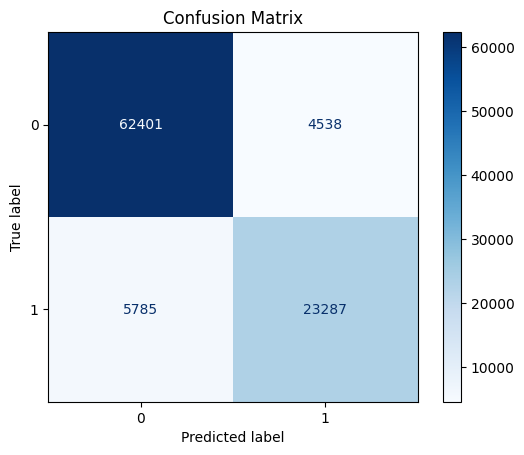

In [14]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

#### ROC Curve
- Visual representation of the trade-off between True Positive Rate (Sensitivity) and False Positive Rate across thresholds
- Shows how well the model separates the two classes (stress and no stress)

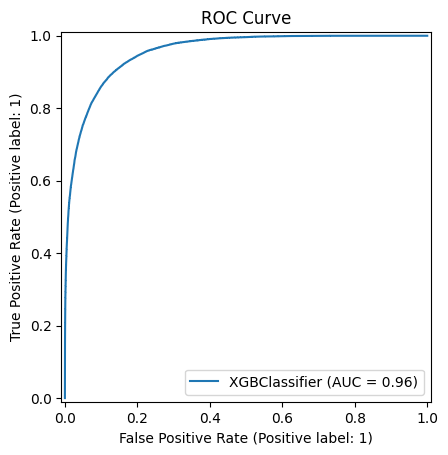

In [15]:
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("ROC Curve")
plt.show()

> **AUC = 0.96**

- This indicates that the model has excellent discriminative ability — it can distinguish stress and non-stress cases with 96% confidence.
- high AUC means the model performs well across various thresholds, making it reliable for real-time stress monitoring.

 ## Areas for Potential Improvement
 - Class Imbalance
   - Class weights in XGBoost

In [21]:
# scale_pos_weight = number of class 0 samples / number of class 1 samples (= 66939 / 29072)
scale_pos_weight = 2.3

xgb_weighted = XGBClassifier(scale_pos_weight=2.3, use_label_encoder=False, eval_metric='logloss')

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1]
}

grid_search_weighted = GridSearchCV(
    estimator=xgb_weighted,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search_weighted.fit(X_train, y_train)

best_model = grid_search_weighted.best_estimator_

print("Best Parameters:", grid_search_weighted.best_params_)

# Predictions
y_pred = best_model.predict(X_test)

# Classification metrics
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Fitting 5 folds for each of 54 candidates, totalling 270 fits


C:\Users\Deepak Dhinwa\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:183: UserWarning: [21:20:40] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Parameters: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}

Classification Report:
               precision    recall  f1-score   support

         0.0       0.95      0.88      0.91     66939
         1.0       0.76      0.89      0.82     29072

    accuracy                           0.88     96011
   macro avg       0.85      0.88      0.86     96011
weighted avg       0.89      0.88      0.88     96011



### Improvements:
- **Recall for stress class (1)** improved significantly (from 0.80 → 0.89).
- The model now detects more stress cases, which is critical in real-world applications.
- Minor trade-off in precision (0.84 → 0.76) is acceptable considering the benefit in recall.

> This final model is balanced and well-optimized for the real-world need of early stress detection.

#### Comparison Bar Plot

C:\Users\Deepak Dhinwa\AppData\Local\Temp\ipykernel_14780\2310638502.py:48: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Deepak Dhinwa\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


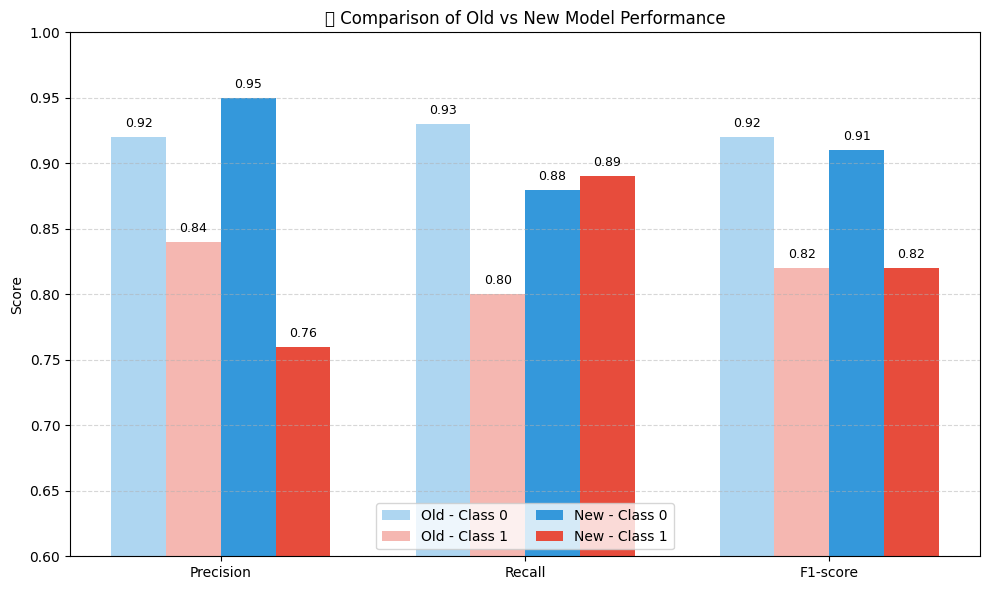

In [23]:
# Old model metrics
old_metrics = {
    "Class 0": [0.92, 0.93, 0.92],  # [precision, recall, f1]
    "Class 1": [0.84, 0.80, 0.82],
}

# New model metrics (after handling imbalance)
new_metrics = {
    "Class 0": [0.95, 0.88, 0.91],
    "Class 1": [0.76, 0.89, 0.82],
}

labels = ['Precision', 'Recall', 'F1-score']
x = np.arange(len(labels))  # [0, 1, 2]
width = 0.18

fig, ax = plt.subplots(figsize=(10, 6))

# Bar positions
ax.bar(x - width*1.5, old_metrics['Class 0'], width, label='Old - Class 0', color='#AED6F1')
ax.bar(x - width*0.5, old_metrics['Class 1'], width, label='Old - Class 1', color='#F5B7B1')
ax.bar(x + width*0.5, new_metrics['Class 0'], width, label='New - Class 0', color='#3498DB')
ax.bar(x + width*1.5, new_metrics['Class 1'], width, label='New - Class 1', color='#E74C3C')

# Labels and title
ax.set_ylabel('Score')
ax.set_title('📊 Comparison of Old vs New Model Performance')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0.6, 1.0)
ax.legend(loc='lower center', ncol=2)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Show value on top of bars
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 5),  # offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

# Apply labels
for container in ax.containers:
    autolabel(container)

plt.tight_layout()
plt.show()